Stage 07 histogram and contrast Equlizer 

In [1]:
# Cell 1 — imports, settings, input
from pathlib import Path
import csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = Path("data") / "task02_uneven.jpg"
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
TARGET_WIDTH = 800
print("OpenCV version:", cv2.__version__)

image = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)
if image is None:
    raise FileNotFoundError(f"Could not read the image: {IMAGE_PATH}")
h, w = image.shape[:2]
img = cv2.resize(image, (TARGET_WIDTH, round(h * TARGET_WIDTH / w)), interpolation=cv2.INTER_AREA)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print(f"Resized {img.shape[1]} x {img.shape[0]} | gray mean {gray.mean():.1f}, "
      f"min {gray.min()}, max {gray.max()}, std {gray.std():.1f}")

OpenCV version: 5.0.0
Resized 800 x 1067 | gray mean 112.5, min 1, max 255, std 43.6


Histograms of B, G, R and grayscale (requirement 1)

channel       mean  min  max    std  peak at
B (blue)      79.7    1  255   44.2       36
G (green)    109.2    0  255   44.3       80
R (red)      131.6    0  255   44.8      107
Grayscale    112.5    1  255   43.6       85


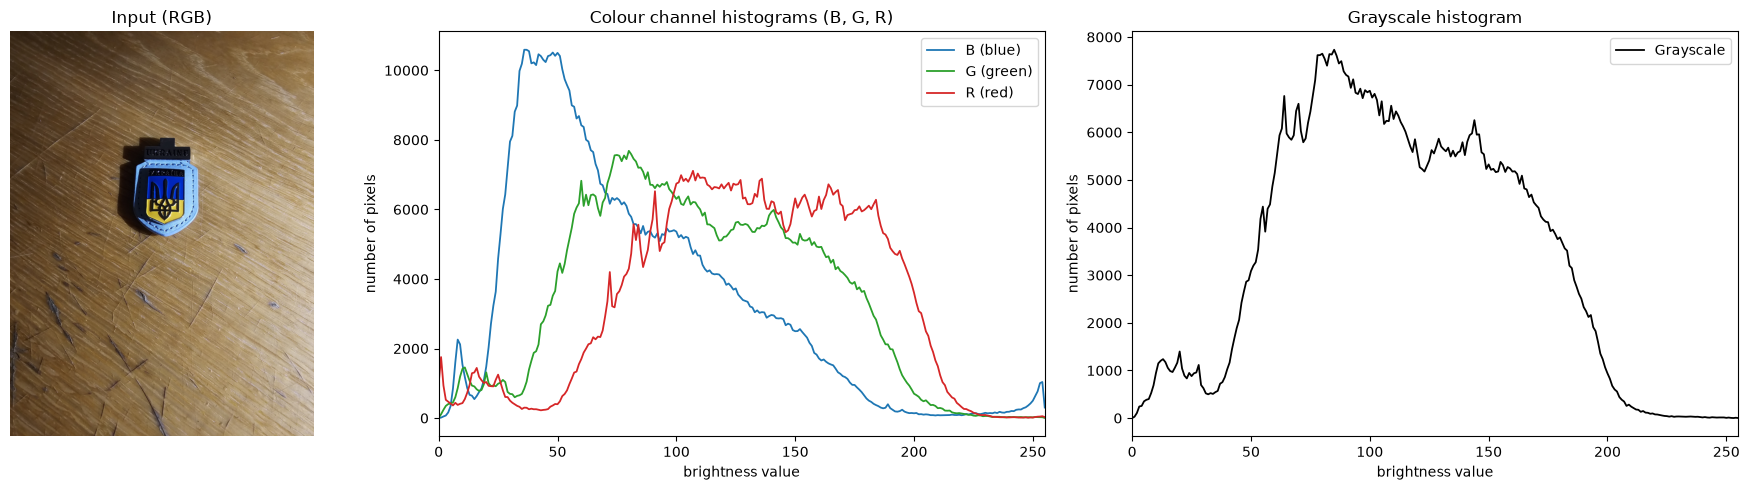

In [2]:
# Cell 2 — channel histograms of the original image
def hist(channel):
    """256-bin histogram of one 8-bit channel."""
    return cv2.calcHist([channel], [0], None, [256], [0, 256]).ravel()

b, g, r = cv2.split(img)
channels = {"B (blue)": (b, "tab:blue"), "G (green)": (g, "tab:green"),
            "R (red)": (r, "tab:red"), "Grayscale": (gray, "black")}

print(f"{'channel':<11}{'mean':>7}{'min':>5}{'max':>5}{'std':>7}{'peak at':>9}")
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Input (RGB)")
axes[0].axis("off")

for name, (ch, color) in channels.items():
    hst = hist(ch)
    print(f"{name:<11}{ch.mean():>7.1f}{ch.min():>5}{ch.max():>5}{ch.std():>7.1f}{int(hst.argmax()):>9}")
    ax = axes[2] if name == "Grayscale" else axes[1]
    ax.plot(hst, color=color, label=name, linewidth=1.3)

axes[1].set_title("Colour channel histograms (B, G, R)")
axes[2].set_title("Grayscale histogram")
for ax in axes[1:]:
    ax.set_xlim(0, 255)
    ax.set_xlabel("brightness value")
    ax.set_ylabel("number of pixels")
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task06_step2_histograms_original.png", dpi=150, bbox_inches="tight")
plt.show()

Step 3 — Histogram equalization 

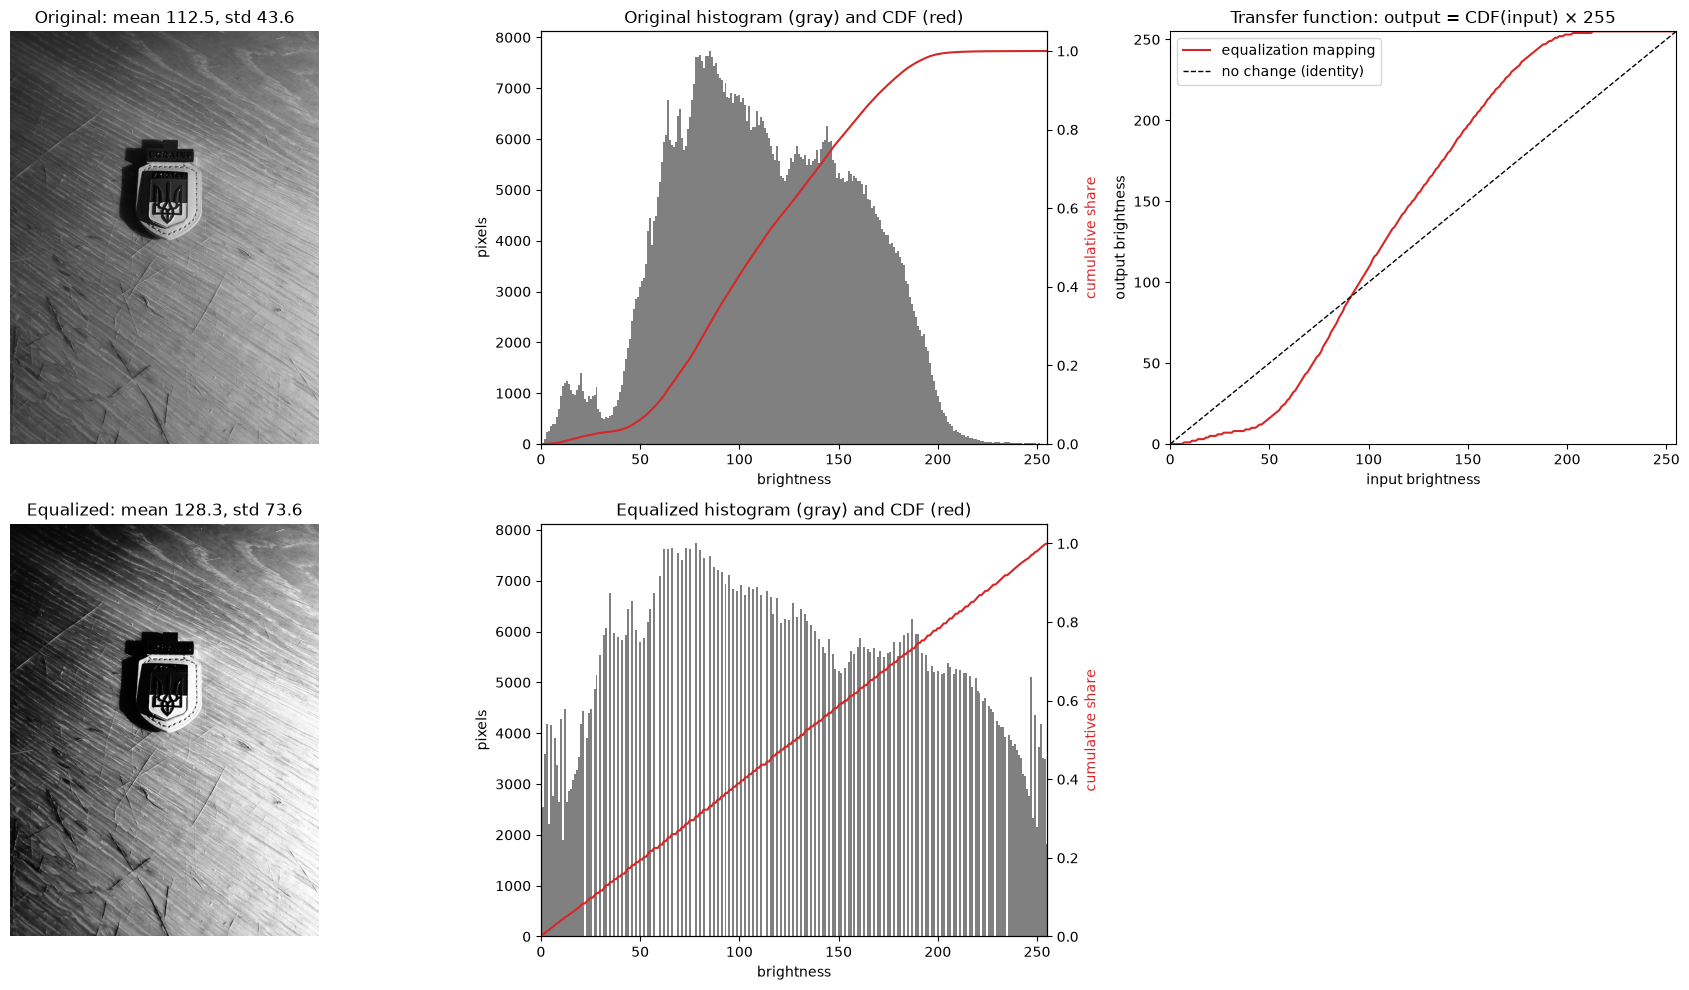

Equalized: mean 128.3, min 0, max 255, std 73.6


In [3]:
# Cell 3 — global histogram equalization + cumulative distribution
equalized = cv2.equalizeHist(gray)
_ = cv2.imwrite(str(RESULTS_DIR / "task06_equalized.png"), equalized)

def cdf_norm(hst):
    """Cumulative distribution scaled to 0..1."""
    c = hst.cumsum()
    return c / c[-1]

h_orig, h_eq = hist(gray), hist(equalized)
mapping = np.round(cdf_norm(h_orig) * 255)          # the transfer function of equalization

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for row, (name, im, hst) in enumerate([("Original", gray, h_orig), ("Equalized", equalized, h_eq)]):
    axes[row, 0].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"{name}: mean {im.mean():.1f}, std {im.std():.1f}")
    axes[row, 0].axis("off")
    ax = axes[row, 1]
    ax.bar(np.arange(256), hst, width=1.0, color="gray")
    ax2 = ax.twinx()                                  # second y-axis for the CDF
    ax2.plot(cdf_norm(hst), color="tab:red", linewidth=1.5)
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel("cumulative share", color="tab:red")
    ax.set_xlim(0, 255)
    ax.set_title(f"{name} histogram (gray) and CDF (red)")
    ax.set_xlabel("brightness")
    ax.set_ylabel("pixels")

axes[0, 2].plot(np.arange(256), mapping, color="tab:red", label="equalization mapping")
axes[0, 2].plot([0, 255], [0, 255], "k--", linewidth=1, label="no change (identity)")
axes[0, 2].set_xlim(0, 255)
axes[0, 2].set_ylim(0, 255)
axes[0, 2].set_xlabel("input brightness")
axes[0, 2].set_ylabel("output brightness")
axes[0, 2].set_title("Transfer function: output = CDF(input) × 255")
axes[0, 2].legend()
axes[1, 2].axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task06_step3_equalization.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Equalized: mean {equalized.mean():.1f}, min {equalized.min()}, max {equalized.max()}, "
      f"std {equalized.std():.1f}")

Step 4 — CLAHE (requirement 3)

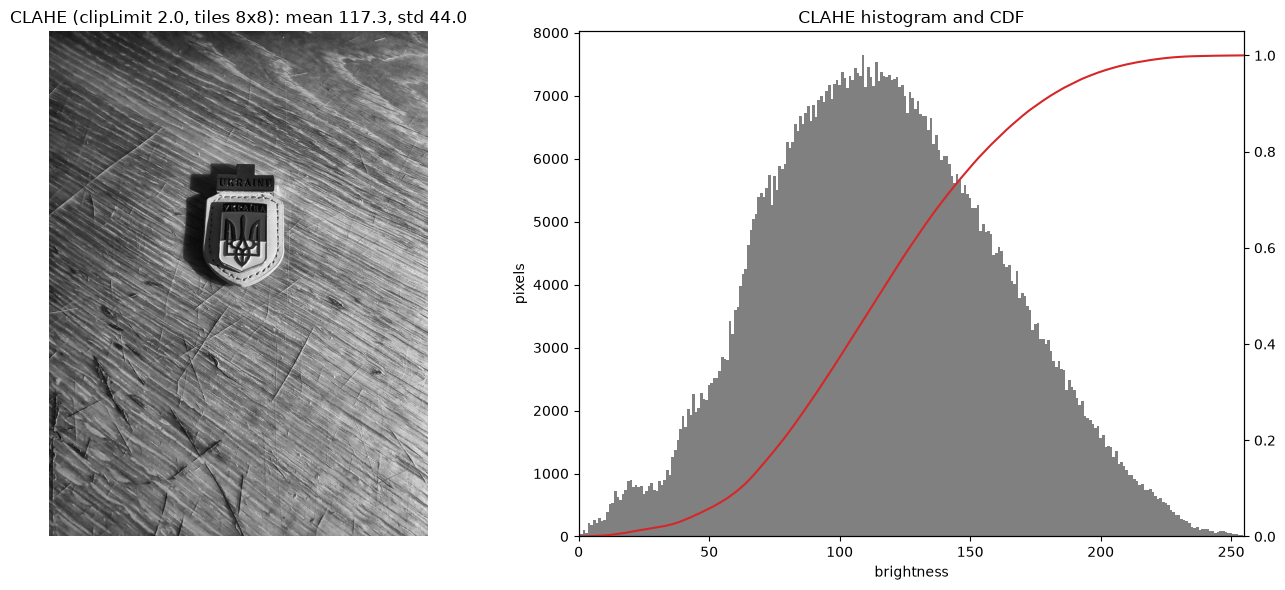

CLAHE: mean 117.3, min 1, max 255, std 44.0


In [4]:
# Cell 4 — CLAHE (contrast-limited adaptive equalization)
CLIP_LIMIT = 2.0
TILE_GRID = (8, 8)

clahe = cv2.createCLAHE(clipLimit=CLIP_LIMIT, tileGridSize=TILE_GRID)
clahe_img = clahe.apply(gray)
_ = cv2.imwrite(str(RESULTS_DIR / "task06_clahe.png"), clahe_img)

h_cl = hist(clahe_img)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(clahe_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"CLAHE (clipLimit {CLIP_LIMIT}, tiles {TILE_GRID[0]}x{TILE_GRID[1]}): "
                  f"mean {clahe_img.mean():.1f}, std {clahe_img.std():.1f}")
axes[0].axis("off")
axes[1].bar(np.arange(256), h_cl, width=1.0, color="gray")
ax2 = axes[1].twinx()
ax2.plot(cdf_norm(h_cl), color="tab:red", linewidth=1.5)
ax2.set_ylim(0, 1.05)
axes[1].set_xlim(0, 255)
axes[1].set_title("CLAHE histogram and CDF")
axes[1].set_xlabel("brightness")
axes[1].set_ylabel("pixels")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task06_step4_clahe.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"CLAHE: mean {clahe_img.mean():.1f}, min {clahe_img.min()}, max {clahe_img.max()}, "
      f"std {clahe_img.std():.1f}")

Step 5 — Comparison and statistics (requirements 4 and 5)

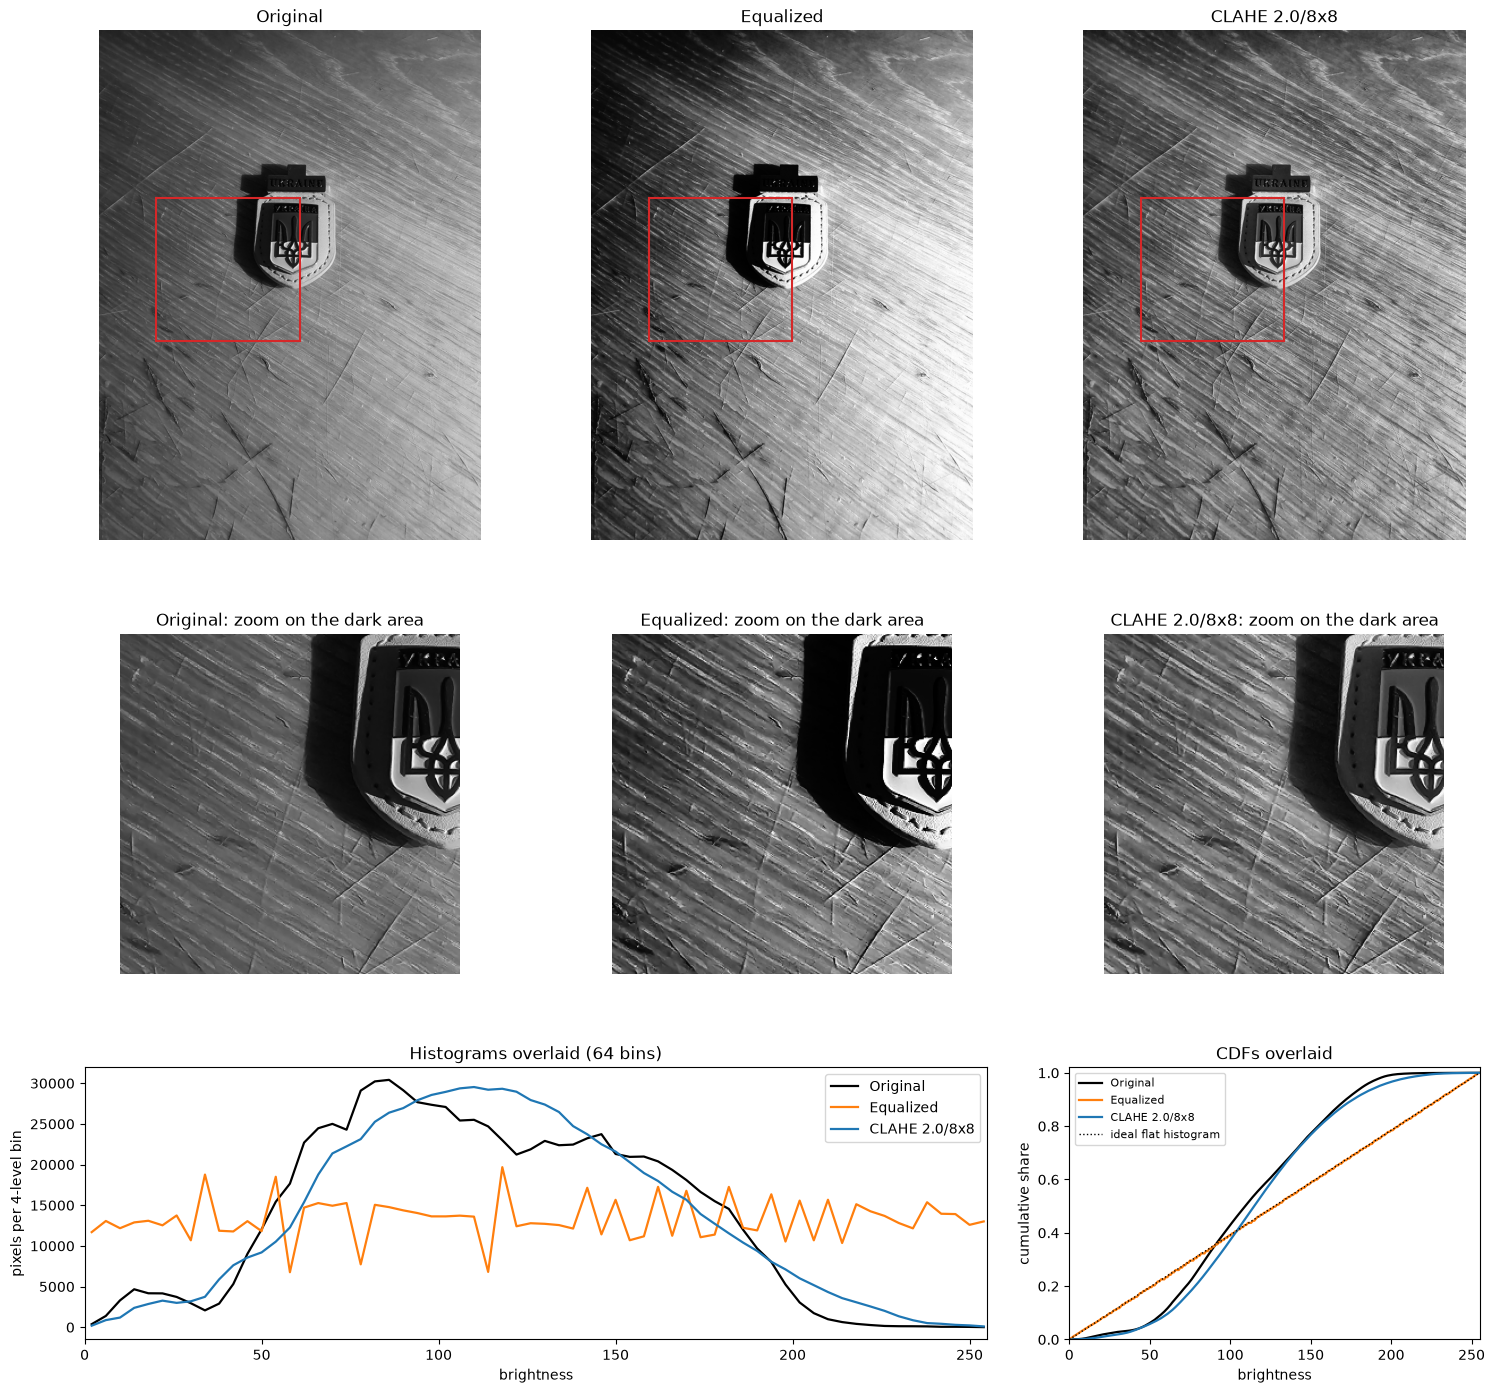

version            mean  min  max    std   local  local L  local R  mean L  mean R
Original          112.5    1  255   43.6    14.5     10.8     12.9    76.7   153.0
Equalized         128.3    0  255   73.6    23.6     20.3     18.9    62.3   197.7
CLAHE 2.0/8x8     117.3    1  255   44.0    28.4     24.0     28.6    92.9   144.5


In [ ]:
# Cell 5 — comparison: images, zoom on the dark area, overlaid histograms and CDFs, statistics
CROP = (350, 650, 120, 420)          # y0, y1, x0, x1: dark left part with the badge's shadow side
TILE = 32                            # tile size for the local contrast measure, px, 
# Tile: in other words, the image is divided into non-overlapping TILE x TILE
#  blocks and the mean standard deviation of all blocks is computed
# smaller title number contains more pixels in each tile. 

versions = {"Original": gray, "Equalized": equalized, f"CLAHE {CLIP_LIMIT}/{TILE_GRID[0]}x{TILE_GRID[1]}": clahe_img}
colors = {"Original": "black", "Equalized": "tab:orange"}
colors[list(versions)[2]] = "tab:blue"

def local_contrast(im, tile=TILE):
    """Mean standard deviation inside non-overlapping tile x tile blocks."""
    H, W = im.shape
    stds = [im[y:y + tile, x:x + tile].std()
            for y in range(0, H - tile + 1, tile) for x in range(0, W - tile + 1, tile)]
    return float(np.mean(stds))

# --- figure: images (row 1), crops (row 2), overlaid histograms + CDFs (row 3) ---
y0, y1, x0, x1 = CROP
fig = plt.figure(figsize=(18, 17))
gs = fig.add_gridspec(3, 3, height_ratios=[3, 2, 1.6], hspace=0.25)
for j, (name, im) in enumerate(versions.items()):
    ax = fig.add_subplot(gs[0, j])
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="tab:red", linewidth=1.5))
    ax.set_title(name)
    ax.axis("off")
    axc = fig.add_subplot(gs[1, j])
    axc.imshow(im[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255)
    axc.set_title(f"{name}: zoom on the dark area")
    axc.axis("off")
# A histogram could count all 256 possible intensity values separately
# pased on bin number 256 divided and intesity values grouped 
# into 64 bins of 4 levels each (0-3, 4-7, ..., 252-255)
ax_h = fig.add_subplot(gs[2, 0:2])
ax_c = fig.add_subplot(gs[2, 2])
for name, im in versions.items():
    h64 = cv2.calcHist([im], [0], None, [64], [0, 256]).ravel()       # 64 bins of 4 levels
    ax_h.plot(np.arange(64) * 4 + 2, h64, color=colors[name], linewidth=1.6, label=name)
    ax_c.plot(cdf_norm(hist(im)), color=colors[name], linewidth=1.6, label=name)
ax_h.set_xlim(0, 255)
ax_h.set_xlabel("brightness")
ax_h.set_ylabel("pixels per 4-level bin")
ax_h.set_title("Histograms overlaid (64 bins)")
ax_h.legend()
ax_c.plot([0, 255], [0, 1], "k:", linewidth=1, label="ideal flat histogram")
ax_c.set_xlim(0, 255)
ax_c.set_ylim(0, 1.02)
ax_c.set_xlabel("brightness")
ax_c.set_ylabel("cumulative share")
ax_c.set_title("CDFs overlaid")
ax_c.legend(fontsize=8)
plt.savefig(RESULTS_DIR / "task06_step5_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

# --- statistics table (required: mean, min, max, std) + local contrast + lighting balance ---
rows = []
print(f"{'version':<16}{'mean':>7}{'min':>5}{'max':>5}{'std':>7}{'local':>8}{'local L':>9}{'local R':>9}{'mean L':>8}{'mean R':>8}")
for name, im in versions.items():
    W = im.shape[1]
    left, right = im[:, :W // 3], im[:, 2 * W // 3:]
    row = [name, round(im.mean(), 1), int(im.min()), int(im.max()), round(im.std(), 1),
           round(local_contrast(im), 1), round(local_contrast(left), 1), round(local_contrast(right), 1),
           round(left.mean(), 1), round(right.mean(), 1)]
    rows.append(row)
    print(f"{row[0]:<16}{row[1]:>7}{row[2]:>5}{row[3]:>5}{row[4]:>7}{row[5]:>8}{row[6]:>9}{row[7]:>9}{row[8]:>8}{row[9]:>8}")

with open(RESULTS_DIR / "task06_statistics.csv", "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f)
    wr.writerow(["version", "mean", "min", "max", "std", "local_contrast", "local_contrast_left",
                 "local_contrast_right", "mean_left_third", "mean_right_third"])
    wr.writerows(rows)

CLAHE parameter experiment (recommended)

 clip    grid    std  local  local L  local R  gap R-L
  1.0     4x4   43.1   21.3     17.1     20.3     60.5
  1.0     8x8   42.6   21.6     17.5     20.8     62.0
  1.0   16x16   42.6   21.8     17.6     20.8     63.9
  2.0     4x4   46.0   27.9     23.2     27.7     49.7
  2.0     8x8   44.0   28.4     24.0     28.6     51.6
  2.0   16x16   43.8   28.6     24.1     28.6     54.5
  4.0     4x4   54.5   38.9     33.7     40.2     31.3
  4.0     8x8   50.6   40.2     35.6     42.4     34.5
  4.0   16x16   49.9   40.9     35.8     42.8     38.3


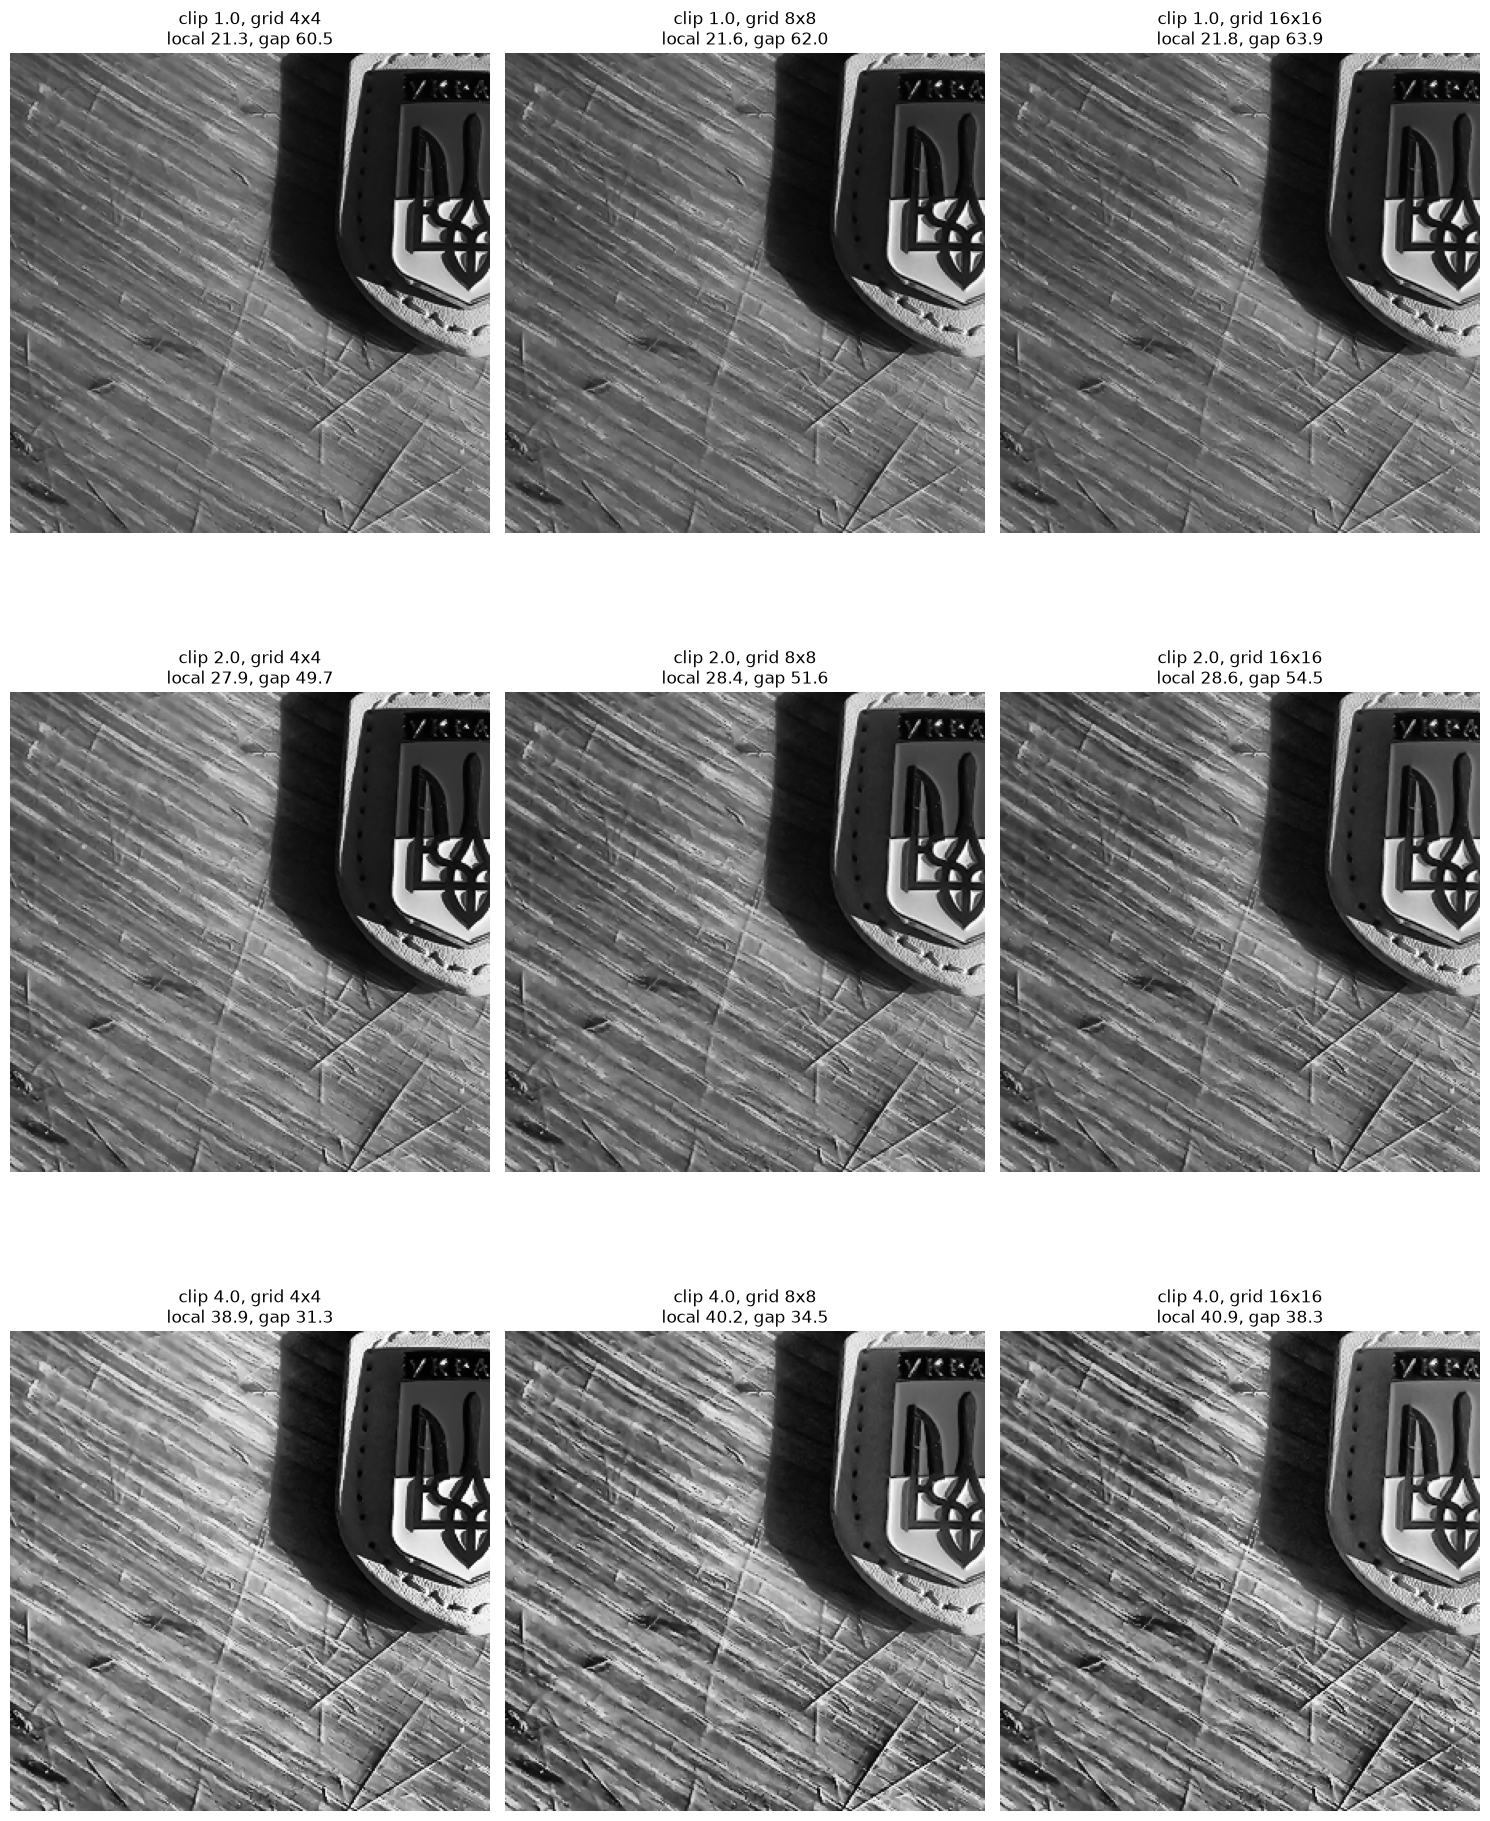

In [6]:
# Cell 6 — CLAHE parameter experiment: clipLimit x tileGridSize
CLIPS = [1.0, 2.0, 4.0]
GRIDS = [(4, 4), (8, 8), (16, 16)]

exp_rows = []
fig, axes = plt.subplots(len(CLIPS), len(GRIDS), figsize=(15, 20))
print(f"{'clip':>5}{'grid':>8}{'std':>7}{'local':>7}{'local L':>9}{'local R':>9}{'gap R-L':>9}")
for i, cl in enumerate(CLIPS):
    for j, grid in enumerate(GRIDS):
        out = cv2.createCLAHE(clipLimit=cl, tileGridSize=grid).apply(gray)
        W = out.shape[1]
        left, right = out[:, :W // 3], out[:, 2 * W // 3:]
        row = [cl, f"{grid[0]}x{grid[1]}", round(out.std(), 1), round(local_contrast(out), 1),
               round(local_contrast(left), 1), round(local_contrast(right), 1),
               round(right.mean() - left.mean(), 1)]
        exp_rows.append(row)
        print(f"{row[0]:>5}{row[1]:>8}{row[2]:>7}{row[3]:>7}{row[4]:>9}{row[5]:>9}{row[6]:>9}")
        ax = axes[i, j]
        ax.imshow(out[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255)       # same zoom as Step 5
        ax.set_title(f"clip {cl}, grid {grid[0]}x{grid[1]}\nlocal {row[3]}, gap {row[6]}")
        ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task06_step6_clahe_parameters.png", dpi=120, bbox_inches="tight")
plt.show()

with open(RESULTS_DIR / "task06_clahe_parameters.csv", "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f)
    wr.writerow(["clip_limit", "tile_grid", "std", "local_contrast", "local_left", "local_right", "gap_right_minus_left"])
    wr.writerows(exp_rows)